# Modeling duration

We want to know whether learned families improve duration estimates. We compare simple baselines, existing categories, family labels, and full features using regression, a decision tree, and an Extra Trees ensemble. A small ANN is optional.

No FMUCD models have been trained yet. Set `RUN_MODELING=True` for the pilot. Keep the test disabled until we have chosen a model from validation results.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
helper_root = Path.cwd() if (Path.cwd() / 'pipeline_utils.py').exists() else Path.cwd() / 'fmucd_analysis'
if str(helper_root) not in sys.path:
    sys.path.insert(0, str(helper_root))
from pipeline_utils import (project_root, read_json, write_json, fingerprint,
                            assert_fingerprints, require_new_run, safe_run_name)
ROOT = project_root()
INPUT_DIR = ROOT / 'data/clustering'
source_manifest = read_json(INPUT_DIR / 'manifest.json')
SEED = 42
pd.set_option('display.max_colwidth', 100)

In [2]:
RUN_MODELING = True
EVALUATE_TEST = True
LOCKED_MODEL_KEY = "full_plus_family__extra_trees"
EMBEDDING_RUN = 'tfidf_review'
FAMILY_RUN = 'families_review'
FAMILY_METHOD = 'text_context'
RUN_NAME = 'duration_pilot'
OVERWRITE = True
MAX_TRAIN_ROWS = 25_000
MAX_VALIDATION_ROWS = 10_000
MAX_TEST_ROWS = 50_000
RUN_ANN = False
TARGET_TRANSFORM = 'none'
EMBED_DIR = ROOT / 'data/embeddings' / safe_run_name(EMBEDDING_RUN)
FAMILY_DIR = ROOT / 'data/families' / safe_run_name(FAMILY_RUN)
OUT_DIR = ROOT / 'data/modeling' / safe_run_name(RUN_NAME)

## 1. Prepare training and validation

We join records, outcomes, embeddings, and family labels by ID. Every model uses the same sampled records and the existing chronological split. Test outcomes stay separate.

In [3]:
if RUN_MODELING:
    import joblib
    import sklearn
    from sklearn.base import clone
    from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import Ridge
    from sklearn.tree import DecisionTreeRegressor
    from sklearn.ensemble import ExtraTreesRegressor
    from sklearn.neural_network import MLPRegressor
    from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
    emb_manifest = read_json(EMBED_DIR / 'manifest.json')
    family_manifest = read_json(FAMILY_DIR / 'manifest.json')
    if family_manifest['embedding_run'] != EMBEDDING_RUN:
        raise ValueError('The selected family and embedding runs do not match.')
    assert_fingerprints(INPUT_DIR, emb_manifest['source_fingerprints'])
    assert_fingerprints(INPUT_DIR, family_manifest['source_fingerprints'])

In [4]:
if RUN_MODELING:
    assert_fingerprints(EMBED_DIR, emb_manifest['artifact_fingerprints'])
    assert_fingerprints(EMBED_DIR, family_manifest['embedding_manifest_fingerprint'])
    assert_fingerprints(FAMILY_DIR, family_manifest['artifact_fingerprints'])
    require_new_run(OUT_DIR, OVERWRITE)
    family_column = f'family_{FAMILY_METHOD}'
    families = pd.read_parquet(FAMILY_DIR / 'task_families.parquet', columns=['task_id', family_column])
    catalog = pd.read_parquet(EMBED_DIR / 'catalog.parquet', columns=['task_id'])
    embedding_matrix = np.load(EMBED_DIR / 'text_context.npy', mmap_mode='r')
    record_columns = ['record_id', 'task_id', 'UniversityID', 'WOPriority', 'PPM/UPM', 'Type',
        'Size', 'BuildingAge', 'SystemCode', 'SubsystemCode', 'DescriptiveCode', 'WOStartDate',
        'StartMonth', 'StartWeekday', 'StartYear', 'known_training_task', 'split']
    records = pd.read_parquet(INPUT_DIR / 'work_order_features.parquet', columns=record_columns)
    assert records['record_id'].is_unique and families['task_id'].is_unique and catalog['task_id'].is_unique
    training_counts = records.loc[records['split'].eq('train'), 'task_id'].value_counts()
    records['training_task_count'] = records['task_id'].map(training_counts).fillna(0).astype('int64')

In [5]:
if RUN_MODELING:
    def sample_split(name, limit):
        part = records.loc[records['split'].eq(name)].copy()
        return part.sample(min(limit, len(part)), random_state=SEED) if limit is not None else part

In [6]:
if RUN_MODELING:
    training = sample_split('train', MAX_TRAIN_ROWS)
    validation = sample_split('validation', MAX_VALIDATION_ROWS)
    assert len(training) and len(validation), 'Training and validation must be nonempty.'
    development_targets = pd.read_parquet(INPUT_DIR / 'work_order_outcomes.parquet',
        filters=[('split', 'in', ['train', 'validation'])])
    assert development_targets['record_id'].is_unique
    embedding_columns = [f'emb_{i}' for i in range(embedding_matrix.shape[1])]
    categorical_context = ['UniversityID', 'WOPriority', 'PPM/UPM', 'Type']
    classification = ['SystemCode', 'SubsystemCode', 'DescriptiveCode']
    numeric_context = ['Size', 'BuildingAge', 'StartMonth', 'StartWeekday', 'StartYear']

In [7]:
if RUN_MODELING:
    def prepare(part, targets):
        joined = part.merge(targets[['record_id', 'task_id', 'split', 'WODuration', 'WOEndDate']],
            on=['record_id', 'task_id', 'split'], validate='one_to_one', how='left')
        assert joined['WODuration'].notna().all() and joined['WODuration'].ge(0).all()
        joined = joined.merge(families, on='task_id', how='left', validate='many_to_one')
        assert joined[family_column].notna().all()
        joined['family_available'] = joined[family_column].ge(0)
        joined[family_column] = joined[family_column].astype('int64').astype(str)
        for column in categorical_context + classification:
            joined[column] = joined[column].astype('string').fillna('Unknown').astype(str)
        positions = pd.Index(catalog['task_id']).get_indexer(joined['task_id'])
        assert (positions >= 0).all(), 'Missing task embedding.'
        vectors = pd.DataFrame(np.asarray(embedding_matrix[positions]), columns=embedding_columns)
        return pd.concat([joined.reset_index(drop=True), vectors], axis=1)

In [8]:
if RUN_MODELING:
    training = prepare(training, development_targets)
    validation = prepare(validation, development_targets)
    assert training['WOEndDate'].lt(pd.Timestamp(source_manifest['train_outcomes_known_before'])).all()
    assert validation['WOStartDate'].ge(pd.Timestamp(source_manifest['train_outcomes_known_before'])).all()
    display(pd.DataFrame({'split': ['train', 'validation'], 'sampled_rows': [len(training), len(validation)],
        'family_assignment_share': [training['family_available'].mean(), validation['family_available'].mean()]}))

,split,sampled_rows,family_assignment_share
0,train,25000,1.0
1,validation,10000,1.0


## 2. Establish the baselines

We start with global, university, task-history, and family estimates. An unseen group falls back to the training mean. These use the same training sample as the learned models.

In [9]:
if RUN_MODELING:
    def metrics(actual, predicted):
        predicted = np.maximum(np.asarray(predicted, dtype=float), 0)
        mse = mean_squared_error(actual, predicted)
        return {'MSE': mse, 'RMSE_days': np.sqrt(mse), 'MAE_days': mean_absolute_error(actual, predicted),
                'R2': r2_score(actual, predicted) if len(actual) > 1 else np.nan}

In [10]:
if RUN_MODELING:
    global_mean = float(training['WODuration'].mean())
    global_median = float(training['WODuration'].median())
    group_means = {column: training.loc[training['family_available'] if column == family_column else
        np.ones(len(training), dtype=bool)].groupby(column)['WODuration'].mean()
        for column in ['UniversityID', 'task_id', family_column]}

In [11]:
if RUN_MODELING:
    def baseline_predictions(part):
        result = {'global_mean': np.full(len(part), global_mean), 'global_median': np.full(len(part), global_median)}
        for column, mapping in group_means.items():
            result[f'mean_by_{column}'] = part[column].map(mapping).fillna(global_mean).to_numpy()
        return result

In [12]:
if RUN_MODELING:
    predictions = baseline_predictions(validation)
    rows = [{'key': name, 'kind': 'baseline', **metrics(validation['WODuration'], pred)}
            for name, pred in predictions.items()]
    display(pd.DataFrame(rows).sort_values('MSE').round(3))

,key,kind,MSE,RMSE_days,MAE_days,R2
1,global_median,baseline,781.944,27.963,17.986,-0.033
3,mean_by_task_id,baseline,853.193,29.209,23.048,-0.127
2,mean_by_UniversityID,baseline,940.522,30.668,25.828,-0.243
4,mean_by_family_text_context,baseline,973.969,31.208,26.478,-0.287
0,global_mean,baseline,1004.614,31.696,27.771,-0.328


## 3. Compare features and models

We compare six feature sets with fixed starting model settings. Duration, completion dates, realized costs, and labor hours are excluded from predictors. MSE is the primary comparison; RMSE and MAE show error in days.

In [13]:
if RUN_MODELING:
    feature_sets = {
        'context': (numeric_context, categorical_context, []),
        'existing_classes': (numeric_context, categorical_context + classification, []),
        'family_only': ([], [family_column], []),
        'context_plus_family': (numeric_context, categorical_context + [family_column], []),
        'full': (numeric_context, categorical_context + classification, embedding_columns),
        'full_plus_family': (numeric_context, categorical_context + classification + [family_column], embedding_columns),
    }
    learners = {
        'ridge': Ridge(alpha=10),
        'decision_tree': DecisionTreeRegressor(max_depth=8, min_samples_leaf=25, random_state=SEED),
        'extra_trees': ExtraTreesRegressor(n_estimators=80, max_depth=20, min_samples_leaf=10,
                                          n_jobs=-1, random_state=SEED),
    }
    if RUN_ANN:
        learners['ann'] = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=200,
            early_stopping=True, random_state=SEED)

In [14]:
if RUN_MODELING:
    if TARGET_TRANSFORM not in {'none', 'log1p'}:
        raise ValueError('Unknown TARGET_TRANSFORM.')
    fitted_models = {}

In [15]:
if RUN_MODELING:
    for experiment, (numeric, categorical, embedded) in feature_sets.items():
        transformers = []
        if numeric:
            transformers.append(('numeric', Pipeline([('impute', SimpleImputer(strategy='median',
                keep_empty_features=True, add_indicator=True)), ('scale', StandardScaler())]), numeric))
        if categorical:
            transformers.append(('categories', OneHotEncoder(handle_unknown='ignore',
                sparse_output=False, min_frequency=10, max_categories=100), categorical))
        if embedded:
            transformers.append(('embedding', 'passthrough', embedded))
        preprocess = ColumnTransformer(transformers, remainder='drop')
        for learner_name, learner in learners.items():
            key = f'{experiment}__{learner_name}'
            estimator = Pipeline([('features', clone(preprocess)), ('model', clone(learner))])
            if TARGET_TRANSFORM == 'log1p':
                estimator = TransformedTargetRegressor(regressor=estimator, func=np.log1p,
                    inverse_func=np.expm1, check_inverse=False)
            estimator.fit(training, training['WODuration'])
            pred = np.maximum(estimator.predict(validation), 0)
            predictions[key] = pred
            fitted_models[key] = estimator
            rows.append({'key': key, 'kind': 'model', **metrics(validation['WODuration'], pred)})

In [16]:
if RUN_MODELING:
    leaderboard = pd.DataFrame(rows).sort_values('MSE').reset_index(drop=True)
    leaderboard.to_csv(OUT_DIR / 'validation_scores.csv', index=False)
    display(leaderboard.round(3))

,key,kind,MSE,RMSE_days,MAE_days,R2
0,full_plus_family__extra_trees,model,615.981,24.819,15.177,0.186
1,full__extra_trees,model,620.167,24.903,15.081,0.180
2,existing_classes__extra_trees,model,693.350,26.332,15.527,0.084
3,existing_classes__decision_tree,model,699.500,26.448,15.544,0.076
4,context_plus_family__extra_trees,model,703.132,26.517,15.209,0.071
5,context_plus_family__decision_tree,model,710.370,26.653,15.776,0.061
6,context__decision_tree,model,730.520,27.028,16.207,0.035
7,context__extra_trees,model,761.085,27.588,15.427,-0.006
8,full__ridge,model,766.517,27.686,16.704,-0.013
9,context__ridge,model,770.338,27.755,16.697,-0.018


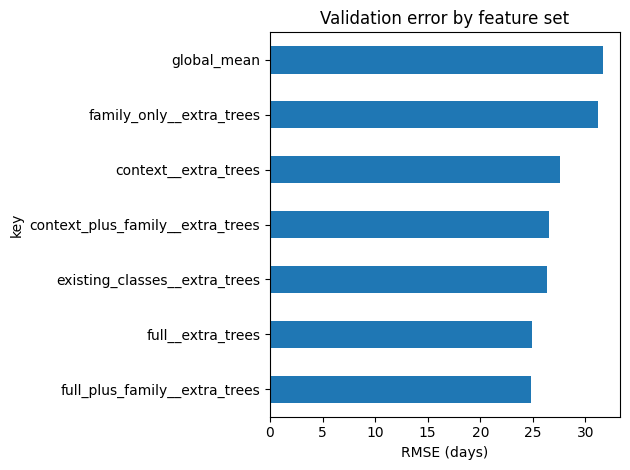

In [17]:
if RUN_MODELING:
    comparison = leaderboard.loc[
        leaderboard['key'].str.endswith('__extra_trees') |
        leaderboard['key'].eq('global_mean')
    ].set_index('key')
    comparison['RMSE_days'].sort_values().plot.barh(
        title='Validation error by feature set', xlabel='RMSE (days)'
    )
    plt.tight_layout()
    plt.show()

Lower error is better. We use the same Extra Trees model for each feature set here. The full and full-plus-family results show whether the family label adds value.

In [18]:
if RUN_MODELING:
    best_model_key = leaderboard.loc[leaderboard['kind'].eq('model')].iloc[0]['key']
    joblib.dump(fitted_models[best_model_key], OUT_DIR / 'best_validation_model.joblib')

## 4. Examine the errors

We check errors by university, family availability, and the amount of task history. We also inspect large misses. A useful improvement should extend beyond the most common tasks.

In [19]:
if RUN_MODELING:
    error_frame = validation[['record_id', 'task_id', 'UniversityID', 'known_training_task',
        'training_task_count', 'family_available', 'WODuration']].copy()
    error_frame['prediction'] = predictions[best_model_key]
    error_frame['absolute_error'] = abs(error_frame['prediction'] - error_frame['WODuration'])
    error_frame['history_band'] = pd.cut(error_frame['training_task_count'],
        bins=[-1, 0, 1, 4, 19, np.inf], labels=['unseen', '1', '2-4', '5-19', '20+'])
    slices = []
    for field in ['UniversityID', 'known_training_task', 'family_available', 'history_band']:
        for value, group in error_frame.groupby(field, observed=True, dropna=False):
            slices.append({'slice': field, 'value': str(value), 'rows': len(group),
                           **metrics(group['WODuration'], group['prediction'])})
    slice_scores = pd.DataFrame(slices)
    display(slice_scores.round(3))

,slice,value,rows,MSE,RMSE_days,MAE_days,R2
0,UniversityID,1,607,1318.781,36.315,25.537,-0.272
1,UniversityID,10,4161,465.441,21.574,12.291,-0.093
2,UniversityID,12,292,617.919,24.858,17.163,-0.259
3,UniversityID,4,1398,581.392,24.112,16.257,0.081
4,UniversityID,6,2192,632.496,25.149,16.534,0.439
5,UniversityID,7,381,879.682,29.659,17.549,0.150
6,UniversityID,8,450,1155.558,33.994,19.059,-0.469
7,UniversityID,9,519,361.850,19.022,11.333,0.027
8,known_training_task,False,4205,633.282,25.165,15.815,-0.010
9,known_training_task,True,5795,603.427,24.565,14.714,0.255


In [20]:
if RUN_MODELING:
    display(error_frame.nlargest(10, 'absolute_error'))

,record_id,task_id,UniversityID,known_training_task,training_task_count,family_available,WODuration,prediction,absolute_error,history_band
8050,1537938,14789148255397593637,8,True,654,True,75.0,366.533160,291.533160,20+
9851,1542367,14789148255397593637,8,True,654,True,92.0,338.020745,246.020745,20+
3567,1537884,5839374072554336162,8,False,0,True,233.0,13.391258,219.608742,unseen
8873,2650207,7233556253217115139,10,True,1325,True,224.0,11.126727,212.873273,20+
2323,1944786,12749734275807076702,10,True,569,True,212.0,9.765105,202.234895,20+
2435,1436200,5315230053425074812,7,True,88,True,232.0,41.807216,190.192784,20+
7614,1805741,14168609388277124311,10,True,6517,True,201.0,11.004719,189.995281,20+
3719,1335938,16045014917411786721,6,True,176,True,227.0,38.491556,188.508444,20+
7580,2597293,8598123162927947871,10,True,6,True,194.0,10.213430,183.786570,5-19
963,127321,3108220541616560822,1,True,416,True,87.0,266.625214,179.625214,20+


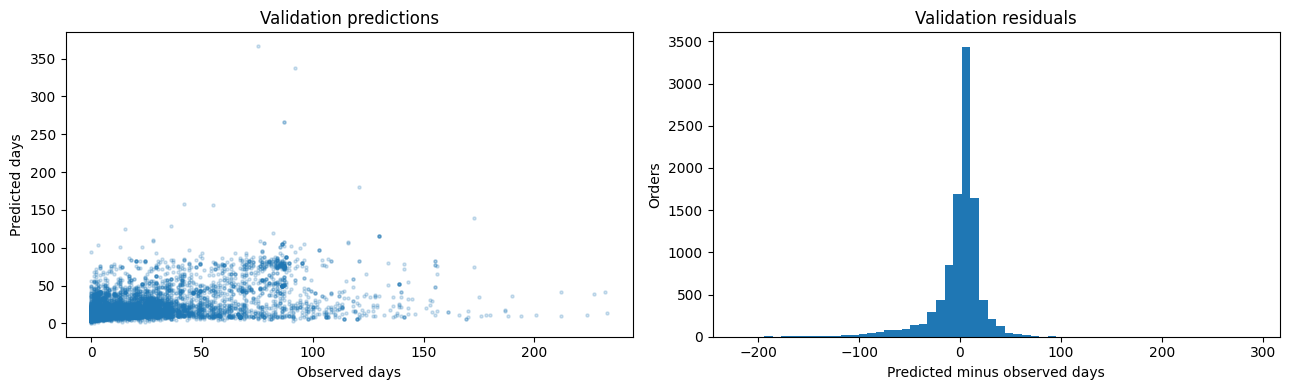

In [21]:
if RUN_MODELING:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].scatter(error_frame['WODuration'], error_frame['prediction'], s=5, alpha=.2)
    axes[0].set(xlabel='Observed days', ylabel='Predicted days', title='Validation predictions')
    axes[1].hist(error_frame['prediction'] - error_frame['WODuration'], bins=60)
    axes[1].set(xlabel='Predicted minus observed days', ylabel='Orders', title='Validation residuals')
    plt.tight_layout()
    plt.show()

In [22]:
if RUN_MODELING:
    error_frame.to_parquet(OUT_DIR / 'validation_predictions.parquet', index=False)
    slice_scores.to_csv(OUT_DIR / 'validation_slices.csv', index=False)
    training[['record_id']].to_parquet(OUT_DIR / 'training_record_ids.parquet', index=False)
    model_manifest = {'stage': 'modeling', 'target': 'WODuration', 'unit': 'elapsed days',
        'embedding_run': EMBEDDING_RUN, 'family_run': FAMILY_RUN, 'family_method': FAMILY_METHOD,
        'seed': SEED, 'target_transform': TARGET_TRANSFORM, 'training_rows': len(training),
        'validation_rows': len(validation), 'max_train_rows': MAX_TRAIN_ROWS,
        'best_validation_model': best_model_key, 'test_evaluated': False,
        'source_fingerprints': fingerprint([INPUT_DIR / 'manifest.json', INPUT_DIR / 'work_order_outcomes.parquet']),
        'upstream_manifests': {'embedding': fingerprint([EMBED_DIR / 'manifest.json']),
                               'families': fingerprint([FAMILY_DIR / 'manifest.json'])},
        'versions': {'sklearn': sklearn.__version__, 'pandas': pd.__version__}}
    write_json(OUT_DIR / 'manifest.json', model_manifest)

## 5. Evaluate the final test

After reviewing validation results, set `LOCKED_MODEL_KEY` and `EVALUATE_TEST=True`. This evaluates the already-fitted candidate against the global-mean baseline. We do not choose or retune the model from test results.

In [23]:
if RUN_MODELING and EVALUATE_TEST:
    if LOCKED_MODEL_KEY not in fitted_models:
        raise ValueError('Set LOCKED_MODEL_KEY to one fitted candidate after reviewing validation results.')
    test_records = sample_split('test', MAX_TEST_ROWS)
    test_targets = pd.read_parquet(INPUT_DIR / 'work_order_outcomes.parquet', filters=[('split', '==', 'test')])
    test = prepare(test_records, test_targets)
    test_prediction = np.maximum(fitted_models[LOCKED_MODEL_KEY].predict(test), 0)
    test_scores = pd.DataFrame([
        {'key': LOCKED_MODEL_KEY, 'rows': len(test), **metrics(test['WODuration'], test_prediction)},
        {'key': 'global_mean', 'rows': len(test), **metrics(test['WODuration'], np.full(len(test), global_mean))},
    ])
    display(test_scores.round(3))

,key,rows,MSE,RMSE_days,MAE_days,R2
0,full_plus_family__extra_trees,50000,549.666,23.445,13.441,-0.076
1,global_mean,50000,1006.881,31.731,28.009,-0.972


In [24]:
if RUN_MODELING and EVALUATE_TEST:
    test_scores.to_csv(OUT_DIR / 'locked_test_scores.csv', index=False)
    joblib.dump(fitted_models[LOCKED_MODEL_KEY], OUT_DIR / 'locked_test_model.joblib')
    test[['record_id', 'task_id', 'WODuration']].assign(prediction=test_prediction).to_parquet(
        OUT_DIR / 'locked_test_predictions.parquet', index=False)
    model_manifest.update(test_evaluated=True, locked_model_key=LOCKED_MODEL_KEY, test_rows=len(test))
    write_json(OUT_DIR / 'manifest.json', model_manifest)

## What we will report

For the presentation, we will show the baseline, full-feature, and full-feature-plus-family results, followed by errors for rare or unseen work. We will report the sample sizes and the selected model, and keep the other comparisons as supporting analysis. Unfinished orders and later-edited descriptions remain limitations of the source data.